In [160]:
# Importamos las librerias que vamos a usar.
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [161]:
# Cargar el archivo CSV con los datos

df = pd.read_csv('datos.csv') # Leemos el archivo .csv

df_1_4 = df[['1.4 ¿Qué usa para cocinar?']]

df_1_5 = df[['1.5 En el hogar, para cocinar tienen:']]

df_1_6 = df[['1.6 De las comidas de la última semana, ¿cuántas fueron preparadas en el hogar?']]

df_1_7 = df[['1.7 Habitualmente cuando se cocina en el hogar, ¿se le agrega sal a las comidas durante la cocción?']]

col_1_4 = '1.4 ¿Qué usa para cocinar?'

categorias_1_4 = [
    'Gas de red',
    'Garrafa',
    'Leña'
]

conteo_1_4 = {
    cat: df_1_4[col_1_4].str.contains(cat, case=False, na=False, regex=False).sum()
    for cat in categorias_1_4
}

df_1_4_estandarizado = pd.DataFrame(list(conteo_1_4.items()), columns=['Elemento', 'fi'])
print("=== 1.4 QUÉ USA PARA COCINAR (ESTANDARIZADO) ===")
print(df_1_4_estandarizado)


# ==========================================
# 2. ESTANDARIZACIÓN PREGUNTA 1.5
# ==========================================
col_1_5 = '1.5 En el hogar, para cocinar tienen:'

categorias_1_5 = [
    'Cocina a gas',
    'Microondas',
    'Horno eléctrico',
    'Cocina a leña'
]

conteo_1_5 = {
    cat: df_1_5[col_1_5].str.contains(cat, case=False, na=False, regex=False).sum()
    for cat in categorias_1_5
}

df_1_5_estandarizado = pd.DataFrame(list(conteo_1_5.items()), columns=['Elemento', 'fi'])
print("\n=== 1.5 EQUIPAMIENTO PARA COCINAR (ESTANDARIZADO) ===")
print(df_1_5_estandarizado)

=== 1.4 QUÉ USA PARA COCINAR (ESTANDARIZADO) ===
     Elemento  fi
0  Gas de red  17
1     Garrafa  34
2        Leña   2

=== 1.5 EQUIPAMIENTO PARA COCINAR (ESTANDARIZADO) ===
          Elemento  fi
0     Cocina a gas  49
1       Microondas  14
2  Horno eléctrico   5
3    Cocina a leña   1


In [162]:
df_1_4_estandarizado.head()

,Elemento,fi
0,Gas de red,17
1,Garrafa,34
2,Leña,2


In [163]:
df_1_5_estandarizado.head()

,Elemento,fi
0,Cocina a gas,49
1,Microondas,14
2,Horno eléctrico,5
3,Cocina a leña,1


In [164]:
df_1_6.head()

,"1.6 De las comidas de la última semana, ¿cuántas fueron preparadas en el hogar?"
0,Casi todas
1,Todas
2,Todas
3,Casi todas
4,Todas


In [165]:
df_1_7.head()

,"1.7 Habitualmente cuando se cocina en el hogar, ¿se le agrega sal a las comidas durante la cocción?"
0,Sí
1,Sí
2,Sí
3,Sí
4,Sí


In [166]:
conteo3 = df_1_6['1.6 De las comidas de la última semana, ¿cuántas fueron preparadas en el hogar?'].value_counts()

# 2. Lo convertís a DataFrame
df_1_6_conteo = pd.DataFrame(conteo3)
df_1_6_conteo

,count
"1.6 De las comidas de la última semana, ¿cuántas fueron preparadas en el hogar?",
Todas,41
Casi todas,10
Pocas,1


In [167]:
conteo4 = df_1_7['1.7 Habitualmente cuando se cocina en el hogar, ¿se le agrega sal a las comidas durante la cocción?'].value_counts()

# 2. Lo convertís a DataFrame
df_1_7_conteo = pd.DataFrame(conteo4)
df_1_7_conteo

,count
"1.7 Habitualmente cuando se cocina en el hogar, ¿se le agrega sal a las comidas durante la cocción?",
Sí,45
No,7


In [168]:
df_1_6_conteo = df_1_6_conteo.rename(columns={'count':'fi'})
df_1_7_conteo = df_1_7_conteo.rename(columns={'count':'fi'})

Garrafa


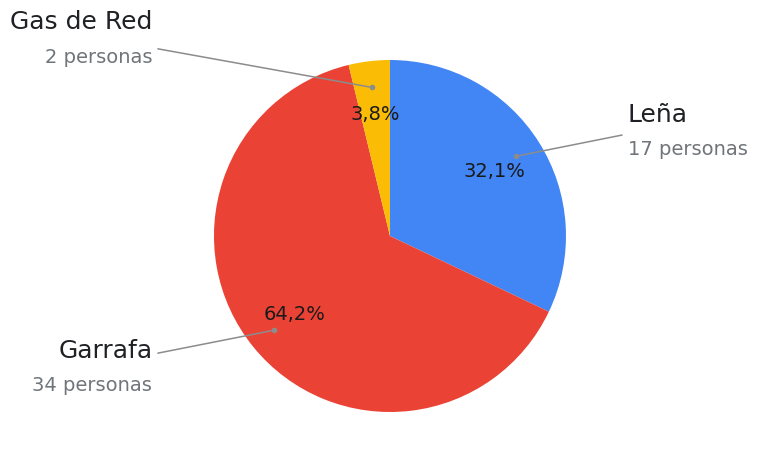

In [169]:
# Devuelve una Series con la(s) categoría(s) modal(es)
moda = df['1.4 ¿Qué usa para cocinar?'].mode()
print(moda[0])  # Imprime la categoría

# 1. Etiquetas y valores
etiquetas_personalizadas = [
    'Leña',
    'Garrafa',
    'Gas de Red'
]
valores = df_1_4_estandarizado['fi'].values
total = sum(valores)

# Paleta estilo Google
colores_google = ['#4285F4', '#EA4335', '#FBBC05', '#34A853']

# 2. Configurar la figura
fig, ax = plt.subplots(figsize=(9, 5.5), subplot_kw=dict(aspect="equal"))

# Graficar la torta mostrando el porcentaje adentro
wedges, texts, autotexts = ax.pie(
    valores,
    autopct=lambda p: f"{p:.1f}%".replace('.', ','),
    pctdistance=0.7,
    colors=colores_google[:len(valores)],
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=1, edgecolor='none')
)

# Estilo de los porcentajes internos
for at in autotexts:
    at.set_color('#1a1a1a')
    at.set_fontsize(14)
    at.set_fontweight('medium')

# 3. Líneas guía hacia afuera con nombre y "X personas" debajo
for i, p in enumerate(wedges):
    ang = (p.theta2 - p.theta1) / 2.0 + p.theta1
    y = np.sin(np.deg2rad(ang))
    x = np.cos(np.deg2rad(ang))
    
    # Coordenadas del punto sobre la cuña
    x_punto, y_punto = 0.85 * x, 0.85 * y
    
    # Coordenadas externas
    horizontal_alignment = {-1: "right", 1: "left"}[int(np.sign(x))]
    x_afuera = 1.35 * np.sign(x)
    y_afuera = 1.15 * y
    
    # Punto gris sobre la cuña
    ax.plot(x_punto, y_punto, marker='o', markersize=3, color='#8c8c8c')
    
    # Texto de cantidad: "1 persona" o "X personas"
    cant = int(valores[i])
    texto_personas = f"{cant} persona" if cant == 1 else f"{cant} personas"
    
    # Nombre de la categoría con la línea guía
    ax.annotate(
        f"{etiquetas_personalizadas[i]}\n",
        xy=(x_punto, y_punto),
        xytext=(x_afuera, y_afuera),
        horizontalalignment=horizontal_alignment,
        verticalalignment="center",
        fontsize=18,
        color="#202124",
        arrowprops=dict(arrowstyle="-", color="#8c8c8c", lw=1.1)
    )
    
    # Subtexto gris justo debajo
    ax.text(
        x_afuera,
        y_afuera - 0.12,
        texto_personas,
        horizontalalignment=horizontal_alignment,
        verticalalignment="center",
        fontsize=14,
        color="#70757a"
    )

plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)
plt.show()

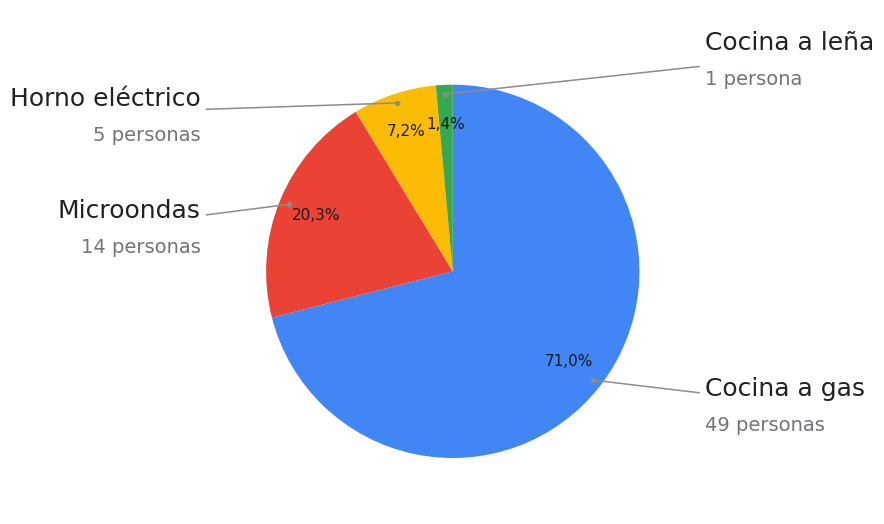

In [189]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Etiquetas y valores
etiquetas_personalizadas = [
    'Cocina a gas',
    'Microondas',
    'Horno eléctrico',
    'Cocina a leña'
]
valores = df_1_5_estandarizado['fi'].values
total = sum(valores)

colores_google = ['#4285F4', '#EA4335', '#FBBC05', '#34A853']

# 2. Configurar la figura
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw=dict(aspect="equal"))

wedges, texts, autotexts = ax.pie(
    valores,
    autopct=lambda p: f"{p:.1f}%".replace('.', ','),
    pctdistance=0.79,
    colors=colores_google[:len(valores)],
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=1, edgecolor='none')
)
# Estilo de los porcentajes internos

for at in autotexts:
    at.set_color('#1a1a1a')
    at.set_fontsize(11)
    at.set_fontweight('medium')

# 3. Dibujar líneas guía con "Cocina a leña" hacia la derecha
for i, p in enumerate(wedges):
    ang = (p.theta2 - p.theta1) / 2.0 + p.theta1
    y = np.sin(np.deg2rad(ang))
    x = np.cos(np.deg2rad(ang))
    
    x_punto, y_punto = 0.95 * x, 0.95 * y
    
    # Si es "Cocina a leña", forzamos lado derecho (+1) y elevación en Y
    if etiquetas_personalizadas[i] == 'Cocina a leña':
        lado = 1
        x_afuera = 1.35
        y_afuera = 1.15
    else:
        lado = -1 if x < 0 else 1
        x_afuera = 1.35 * lado
        y_afuera = 1.15 * y
        
        # Ajuste fino para evitar solapamiento entre Horno eléctrico y Microondas a la izquierda
        if etiquetas_personalizadas[i] == 'Horno eléctrico':
            y_afuera = 0.85
        elif etiquetas_personalizadas[i] == 'Microondas':
            y_afuera = 0.25

    horizontal_alignment = {-1: "right", 1: "left"}[lado]

    # Punto gris sobre la cuña
    ax.plot(x_punto, y_punto, marker='o', markersize=3, color='#8c8c8c')
    
    cant = int(valores[i])
    texto_personas = f"{cant} persona" if cant == 1 else f"{cant} personas"
    
    # Etiqueta de la categoría con la línea guía
    ax.annotate(
        f"{etiquetas_personalizadas[i]}\n",
        xy=(x_punto, y_punto),
        xytext=(x_afuera, y_afuera),
        horizontalalignment=horizontal_alignment,
        verticalalignment="center",
        fontsize=18,
        color="#202124",
        arrowprops=dict(arrowstyle="-", color="#8c8c8c", lw=1.1)
    )
    
    # Subtexto gris debajo
    ax.text(
        x_afuera,
        y_afuera - 0.12,
        texto_personas,
        horizontalalignment=horizontal_alignment,
        verticalalignment="center",
        fontsize=14,
        color="#70757a"
    )

ax.set_xlim(-1.9, 1.9)
ax.set_ylim(-1.3, 1.4)
plt.subplots_adjust(left=0.05, right=0.95, top=0.92, bottom=0.08)
plt.show()

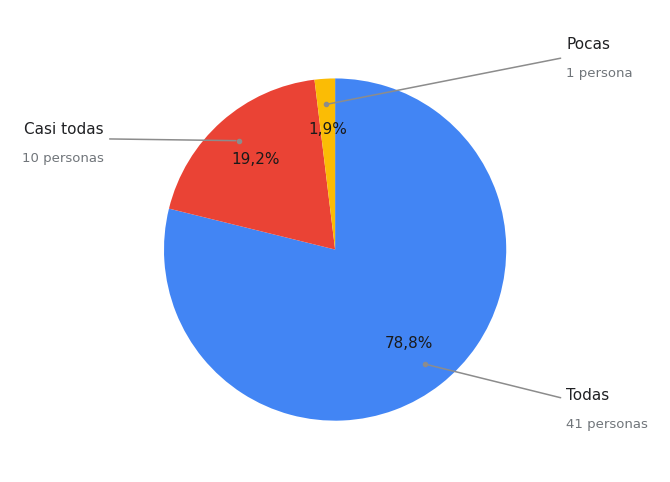

In [191]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Asegurar nombres y valores de la tabla
etiquetas = df_1_6_conteo.index.tolist()
valores = df_1_6_conteo['fi'].values
total = sum(valores)

# 3 colores distintos estilo Google para las 3 porciones
colores_google = ['#4285F4', '#EA4335', '#FBBC05']  # Azul, Rojo, Amarillo

# 2. Configurar la figura
fig, ax = plt.subplots(figsize=(9.5, 5.5), subplot_kw=dict(aspect="equal"))

# Graficar la torta con el porcentaje adentro
wedges, texts, autotexts = ax.pie(
    valores,
    autopct=lambda p: f"{p:.1f}%".replace('.', ','),
    pctdistance=0.7,
    colors=colores_google[:len(valores)],
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=1, edgecolor='none')
)

# Estilo de los porcentajes internos
for at in autotexts:
    at.set_color('#1a1a1a')
    at.set_fontsize(11)
    at.set_fontweight('medium')

# 3. Líneas guía hacia afuera ("Pocas" hacia la derecha)
for i, p in enumerate(wedges):
    ang = (p.theta2 - p.theta1) / 2.0 + p.theta1
    y = np.sin(np.deg2rad(ang))
    x = np.cos(np.deg2rad(ang))

    # Coordenadas del punto sobre la cuña
    x_punto, y_punto = 0.85 * x, 0.85 * y

    # Forzar "Pocas" al cuadrante superior derecho
    nombre = str(etiquetas[i]).strip()
    if 'Pocas' in nombre:
        lado = 1
        x_afuera = 1.35
        y_afuera = 1.15
    else:
        lado = -1 if x < 0 else 1
        x_afuera = 1.35 * lado
        y_afuera = 1.15 * y
        
        # Ajuste vertical para "Casi todas" para que quede balanceada
        if 'Casi todas' in nombre:
            y_afuera = 0.65

    horizontal_alignment = {-1: "right", 1: "left"}[lado]

    # Punto gris sobre la cuña
    ax.plot(x_punto, y_punto, marker='o', markersize=3, color='#8c8c8c')

    # Texto de cantidad
    cant = int(valores[i])
    texto_personas = f"{cant} persona" if cant == 1 else f"{cant} personas"

    # Etiqueta de la categoría con la línea guía
    ax.annotate(
        f"{etiquetas[i]}\n",
        xy=(x_punto, y_punto),
        xytext=(x_afuera, y_afuera),
        horizontalalignment=horizontal_alignment,
        verticalalignment="center",
        fontsize=11,
        color="#202124",
        arrowprops=dict(arrowstyle="-", color="#8c8c8c", lw=1.1)
    )

    # Subtexto gris debajo
    ax.text(
        x_afuera,
        y_afuera - 0.12,
        texto_personas,
        horizontalalignment=horizontal_alignment,
        verticalalignment="center",
        fontsize=9.5,
        color="#70757a"
    )

ax.set_xlim(-1.9, 1.9)
ax.set_ylim(-1.3, 1.4)
plt.subplots_adjust(left=0.08, right=0.92, top=0.92, bottom=0.08)
plt.show()

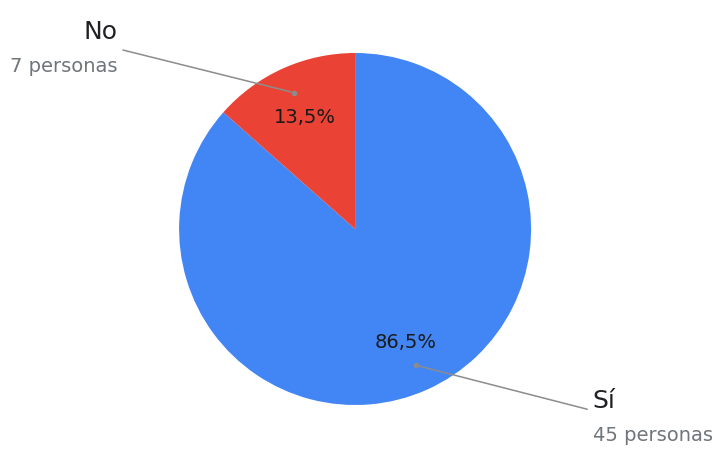

In [193]:
# 1. Asegurar nombres y valores de la tabla

etiquetas = df_1_7_conteo.index.tolist()
valores = df_1_7_conteo['fi'].values
total = sum(valores)

# Colores estilo Google (Azul y Rojo)
colores_google = ['#4285F4', '#EA4335']

# 2. Configurar la figura
fig, ax = plt.subplots(figsize=(9, 5.5), subplot_kw=dict(aspect="equal"))

# Graficar la torta con el porcentaje adentro
wedges, texts, autotexts = ax.pie(
    valores,
    autopct=lambda p: f"{p:.1f}%".replace('.', ','),
    pctdistance=0.7,
    colors=colores_google[:len(valores)],
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=1, edgecolor='none')
)

# Estilo de los porcentajes internos
for at in autotexts:
    at.set_color('#1a1a1a')
    at.set_fontsize(14)
    at.set_fontweight('medium')

# 3. Líneas guía hacia afuera con categoría y "X personas" / "X hogares" debajo
for i, p in enumerate(wedges):
    ang = (p.theta2 - p.theta1) / 2.0 + p.theta1
    y = np.sin(np.deg2rad(ang))
    x = np.cos(np.deg2rad(ang))

    # Coordenadas del punto sobre la porción
    x_punto, y_punto = 0.85 * x, 0.85 * y

    # Coordenadas hacia afuera
    horizontal_alignment = {-1: "right", 1: "left"}[int(np.sign(x))]
    x_afuera = 1.35 * np.sign(x)
    y_afuera = 1.15 * y

    # Punto gris sobre la cuña
    ax.plot(x_punto, y_punto, marker='o', markersize=3, color='#8c8c8c')

    # Texto de cantidad
    cant = int(valores[i])
    texto_personas = f"{cant} persona" if cant == 1 else f"{cant} personas"

    # Etiqueta de la categoría con la línea guía
    ax.annotate(
        f"{etiquetas[i]}\n",
        xy=(x_punto, y_punto),
        xytext=(x_afuera, y_afuera),
        horizontalalignment=horizontal_alignment,
        verticalalignment="center",
        fontsize=18,
        color="#202124",
        arrowprops=dict(arrowstyle="-", color="#8c8c8c", lw=1.1)
    )

    # Subtexto gris debajo de la etiqueta
    ax.text(
        x_afuera,
        y_afuera - 0.12,
        texto_personas,
        horizontalalignment=horizontal_alignment,
        verticalalignment="center",
        fontsize=14,
        color="#70757a"
    )

plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)
plt.show()